In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import forecast as F

In [2]:
df = F.load_all(); X = F.make_features(df); y = df["demand"]
ok = X.notna().all(axis=1); X, y = X[ok], y[ok]
train, test = X.index < F.TEST_START, X.index >= F.TEST_START
feats = F.CALENDAR + F.LAGS + F.WEATHER
m = F.fit(X.loc[train, feats], y[train], 1455)
yt = y[test]
pred = pd.Series(m.predict(X.loc[test, feats]), index=yt.index)
err = yt - pred                                   # positive = model too low

bias: 137.9350159734085  RMSE/MAE: 1.315480824641558


<Axes: >

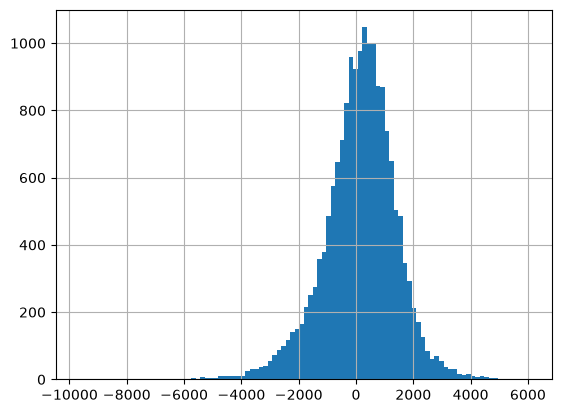

In [3]:
# 1. Bias and error shape
print("bias:", err.mean(), " RMSE/MAE:", np.sqrt((err**2).mean()) / err.abs().mean())
err.hist(bins=100)

In [4]:
# 2. The 5 worst half-hours: what happened?
print(err.abs().sort_values(ascending=False).head(5))

time
2025-12-25 18:00:00+00:00    9691.412714
2025-12-25 18:30:00+00:00    9470.809759
2025-12-25 17:30:00+00:00    9048.319690
2025-12-25 17:00:00+00:00    8501.050916
2025-12-25 19:00:00+00:00    7901.655925
dtype: float64


<Axes: xlabel='time'>

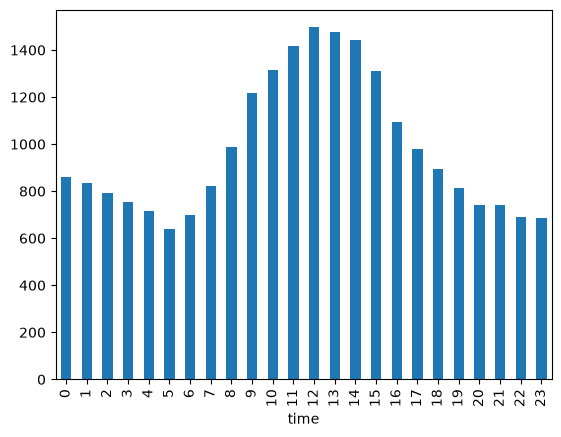

In [5]:
# 3. Error by hour of day (local time)
hour = yt.index.tz_convert("Europe/London").hour
err.abs().groupby(hour).mean().plot(kind="bar")

<Axes: xlabel='time'>

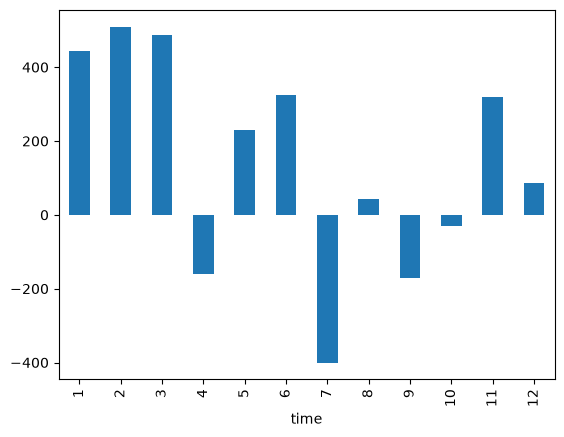

In [6]:
# 4. Bias by month
err.groupby(yt.index.tz_convert("Europe/London").month).mean().plot(kind="bar")

In [8]:
# 5. different baseline: climatology
clim = y[train].groupby([X.loc[train, "half_hour"], X.loc[train, "day_of_week"]]).mean()
c = [clim[(h, d)] for h, d in zip(X.loc[test, "half_hour"], X.loc[test, "day_of_week"])]
print("climatology MAE:", np.abs(yt - c).mean())

climatology MAE: 3832.6046947802884
